In [8]:
! pip install pandas-datareader==0.10.0
! pip install pyxlsb

import pandas as pd
import pandas_datareader.data as web

tnx = web.DataReader('^TNX', 'yahoo', start='2018-01-01', end='2022-01-01')
btc = web.DataReader('BTC-USD', 'yahoo', start='2018-01-01', end='2022-01-01')
shel = web.DataReader('SHELL.AS', 'yahoo', start='2018-01-01', end='2022-01-01')
asml = web.DataReader('ASML', 'yahoo', start='2018-01-01', end='2022-01-01')

samengevoegd = pd.concat([tnx.add_suffix("_TNX"), btc.add_suffix("_BTC"), shel.add_suffix("_SHEL"), asml.add_suffix("_ASML") ], axis=1)
#samengevoegd

#samengevoegd.isna().mean()

samengevoegd_fill = samengevoegd.ffill().backfill()
#samengevoegd_fill

investeringen = pd.Series([25000, 25000, 25000, 25000], index=["Close_TNX", "Close_BTC", "Close_SHEL", "Close_ASML"])
#print(investeringen.sum())
#investeringen

aankoop_prijzen = samengevoegd_fill.head(1).squeeze()
# Mooiere oplossing: aankoop_prijzen = samengevoegd_fill.loc[samengevoegd.isna().sum(axis=1) == 0, :].head(1).squeeze() 
#print(aankoop_prijzen.loc[["Close_TNX", "Close_BTC", "Close_SHEL", "Close_ASML"]])

aantal_aandelen = investeringen / aankoop_prijzen

portfolio_waarde = (samengevoegd_fill * aantal_aandelen).sum(axis=1)
samengevoegd_fill['portfolio_waarde'] = portfolio_waarde
#print(portfolio_waarde)

begin_prijzen = portfolio_waarde.head(n=1)
eind_prijzen = portfolio_waarde.tail(n=1)

begin_prijzen = begin_prijzen.squeeze()
eind_prijzen = eind_prijzen.squeeze()

verschil = eind_prijzen - begin_prijzen

rendement = verschil / begin_prijzen

#print(rendement * 100)
print(rendement * 100 / 4) # 4 jaren data, dus gedeeld door 4

print(portfolio_waarde.mean())
print(portfolio_waarde.std())

onderwaarde = portfolio_waarde.mean() - 2 * portfolio_waarde.std()
verlies = investeringen.sum() - onderwaarde
verlies

Looking in indexes: https://pypi.org/simple, https://us-python.pkg.dev/colab-wheels/public/simple/
Looking in indexes: https://pypi.org/simple, https://us-python.pkg.dev/colab-wheels/public/simple/
32.810627193886845
123460.77953005253
55837.78997570428


88214.80042135603

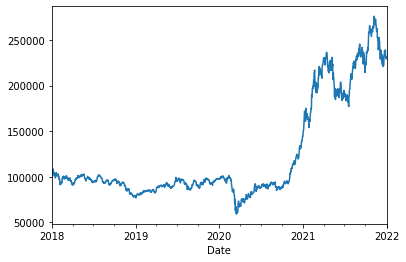

In [11]:
portfolio_waarde.plot()
#plt.show()